# Lab1.2: Supervised Learning

The purpose of this notebook is to explore linear regression and understand how a model learns the best parameters from data.
In this lab
- you will first build and visualize a simple linear regression model
- examine how different parameter values affect the prediction and loss
- and then find the optimal parameters using both **analytic and numerical optimization methods**. 
  - The numerical methods include Batch Gradient Descent and Mini-Batch Stochastic Gradient Descent (Mini-Batch SGD).

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and write code to complete the functions. There are also questions interspersed in the text.


In [1]:
# Math library
import numpy as np
# Plotting library
import matplotlib.pyplot as plt

### 1. Randomly Generate Data

In [2]:
# Create some input(x) / output data(y)
x = np.array([0.03, 0.19, 0.34, 0.46, 0.78, 0.81, 1.08, 1.18, 1.39, 1.60, 1.65, 1.90])
y = np.array([0.67, 0.85, 1.05, 1.0, 1.40, 1.5, 1.3, 1.54, 1.55, 1.68, 1.73, 1.6 ])

print(x)
print(y)

[0.03 0.19 0.34 0.46 0.78 0.81 1.08 1.18 1.39 1.6  1.65 1.9 ]
[0.67 0.85 1.05 1.   1.4  1.5  1.3  1.54 1.55 1.68 1.73 1.6 ]


### 2. 1D Linear Regression(one input, ane output)

---
The 1D linear regression model is defined as:

$$
y = \phi_0 + \phi_1 x
$$

Where:  

- $x$ → input  
- $\phi_0$ → bias / intercept  
- $\phi_1$ → slope / weight


In [3]:
# Define 1D linear regression model
def f(x, phi0, phi1):
  
  y = phi0+(x*phi1)

  return y

In [4]:
# Function to help plot the data
def plot(x, y, phi0, phi1):
    fig,ax = plt.subplots()
    ax.scatter(x,y)
    plt.xlim([0,2.0])
    plt.ylim([0,2.0])
    ax.set_xlabel('Input, $x$')
    ax.set_ylabel('Output, $y$')
    # Draw line
    x_line = np.arange(0, 2, 0.01)
    y_line = f(x_line, phi0, phi1)
    plt.plot(x_line, y_line,'b-',lw=2)

    plt.show()

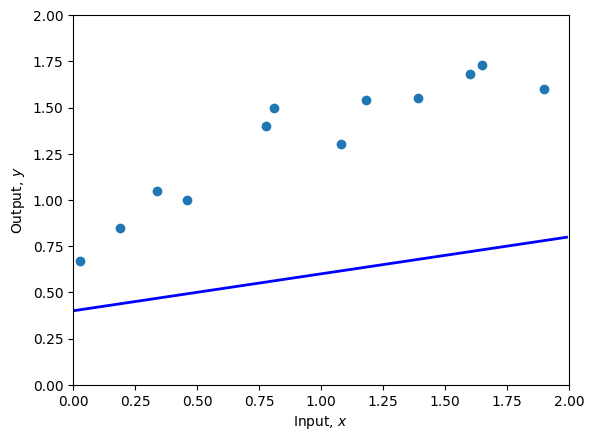

In [5]:
# Set the intercept and slope manually to see how the model fits the data
phi0 = 0.4 ; phi1 = 0.2
# Plot the data and the model
plot(x,y,phi0,phi1)

### 3. Loss Functions for 1D Linear Regression

<details>
<summary>1. Mean Squared Error (MSE)</summary>

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - (\phi_0 + \phi_1 x_i))^2
$$

**Explanation:**

- Measures the **average squared difference** between the predicted values and the actual values.  
- Squaring the error **penalizes large errors more heavily**, so MSE is **sensitive to outliers**.  
- Commonly used in **linear regression** because it has nice mathematical properties for optimization (differentiable, convex).  

</details>

......
<details>
<summary>2. Mean Absolute Error (MAE)</summary>

$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - (\phi_0 + \phi_1 x_i)|
$$

**Explanation:**

- Measures the **average absolute difference** between the predicted values and the actual values.  
- Less sensitive to outliers compared to MSE because errors are **not squared**.  
- MAE is useful when you want a **robust metric** that treats all errors equally.  

</details>


In [6]:
# Function to calculate the loss, you can chose one amoung of two loss-equations above
def compute_loss(x,y,phi0,phi1):   # MSE

  # Predicted function
  y_pred = phi0 + phi1 * x

  # Mean Squared Error
  loss = np.mean(np.square(y - y_pred))

  return loss


def compute_loss_MAE(x,y,phi0,phi1): #MAE
  
  # Predicted function
  y_pred = phi0 + phi1 * x

  # Mean Absolute Error
  loss = np.mean(np.abs(y - y_pred))

  return loss

In [7]:
# Compute the loss for our current model
loss = compute_loss(x,y,phi0,phi1)
print(f'Your Loss = {loss:3.2f}, Ground truth =7.07')

Your Loss = 0.59, Ground truth =7.07


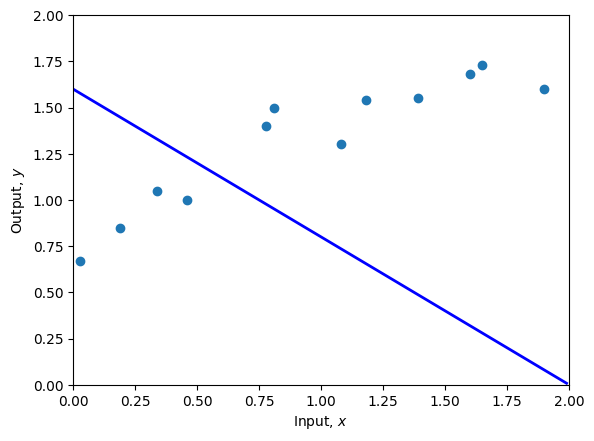

Your Loss = 0.86, Ground truth =10.28


In [8]:
# Set the intercept and slope as in figure 2.2c
phi0 = 1.60 ; phi1 =-0.8
# Plot the data and the model
plot(x,y,phi0,phi1)
loss = compute_loss(x,y,phi0,phi1)
print(f'Your Loss = {loss:3.2f}, Ground truth =10.28')

---

#### Students Turn

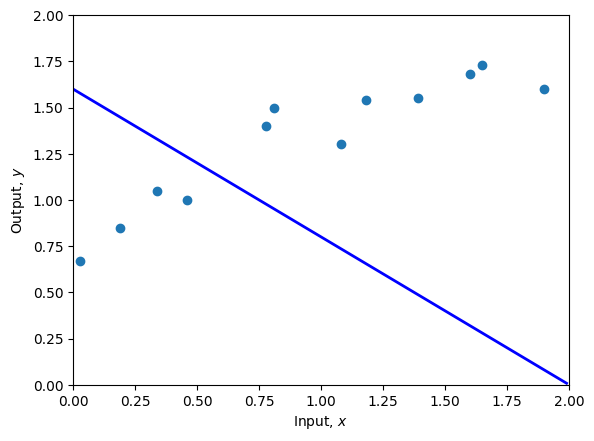

Your Loss = 0.86


In [9]:
# TODO -- Change the parameters manually to fit the model
# First fix phi1 and try changing phi0 until you can't make the loss go down any more
# Then fix phi0 and try changing phi1 until you can't make the loss go down any more
# Repeat this process until you find a set of parameters that fit the model
# You can either do this by hand, or if you want to get fancy, write code to descent automatically in this way
# Start at these values:
phi0 = 1.60 ; phi1 =-0.8

plot(x,y,phi0,phi1)
print(f'Your Loss = {compute_loss(x,y,phi0,phi1):3.2f}')

### 4. Analytic (Closed-Form) Solution

In the previous section, we changed $\phi_0$ and $\phi_1$ manually to reduce the loss.  
For **linear regression with squared-error loss**, we can instead calculate the optimal parameters directly using an **analytic (closed-form) solution**.

Our 1D linear regression model is:

$$
\hat{y}_i = \phi_0 + \phi_1 x_i
$$

where:

- $\phi_0$ is the **bias / intercept**
- $\phi_1$ is the **weight / slope**

#### Step 1: Put the parameters into a vector

We combine the bias and slope into one parameter vector:

$$
\mathbf{w}
=
\begin{bmatrix}
\phi_0 \\
\phi_1
\end{bmatrix}
$$

#### Step 2: Include the bias in the design matrix

To include the bias $\phi_0$ in the matrix multiplication, append a column of ones to the input data:

$$
\mathbf{X}
=
\begin{bmatrix}
1 & x_1 \\
1 & x_2 \\
\vdots & \vdots \\
1 & x_N
\end{bmatrix}
$$

Then all predictions can be written at once as:

$$
\hat{\mathbf{y}} = \mathbf{Xw}
$$

#### Step 3: Define the squared-error objective

We want the predicted values to be as close as possible to the observed values:

$$
L(\mathbf{w}) = \|\mathbf{y}-\mathbf{Xw}\|^2
$$

This expression is the **sum of squared errors (SSE)**.  
The MSE used by `compute_loss()` is simply $\frac{1}{N}$ times the SSE, so **SSE and MSE have the same optimal parameters**.

#### Step 4: Find the minimum analytically

Differentiate the loss with respect to $\mathbf{w}$:

$$
\frac{\partial L}{\partial \mathbf{w}}
=
-2\mathbf{X}^{T}(\mathbf{y}-\mathbf{Xw})
$$

At the minimum, set the derivative equal to zero:

$$
\mathbf{X}^{T}\mathbf{Xw}
=
\mathbf{X}^{T}\mathbf{y}
$$

Therefore, the optimal parameter vector is:

$$
\boxed{
\mathbf{w}^{*}
=
(\mathbf{X}^{T}\mathbf{X})^{-1}\mathbf{X}^{T}\mathbf{y}
}
$$

This is called the **normal equation**.

> **Note:** The closed-form solution applies to least-squares linear regression. In practical numerical computing, `np.linalg.solve()` or `np.linalg.pinv()` is often preferred to explicitly computing a matrix inverse, but below we use the inverse form so that the code matches the equation directly.


In [10]:
# Analytic (closed-form) solution for 1D linear regression
#.......
x.shape

# Step 1: Convert x to a 2D array with a column of ones for the bias term
X = np.column_stack((np.ones(x.shape), x))

print(X)

# Step 2: Calculate optimal parameters using the normal equation
# w = (X^T * X)^-1 * X^T * y
w = np.linalg.pinv(X.T @ X) @ X.T @ y

print(w)

[[1.   0.03]
 [1.   0.19]
 [1.   0.34]
 [1.   0.46]
 [1.   0.78]
 [1.   0.81]
 [1.   1.08]
 [1.   1.18]
 [1.   1.39]
 [1.   1.6 ]
 [1.   1.65]
 [1.   1.9 ]]
[0.82595005 0.52222607]


In [11]:
# Step 3: Make predictions

y_pred = X @ w

print(y_pred)

[0.84161683 0.925173   1.00350691 1.06617404 1.23328638 1.24895316
 1.3899542  1.44217681 1.55184428 1.66151176 1.68762306 1.81817958]


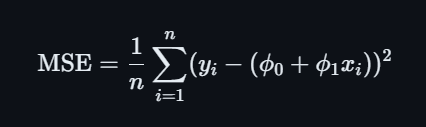

In [12]:
# Step 4: Calculate the loss for the optimal parameters
n = len(y)
print(n)
MSE_loss = 1/n * np.sum((y - y_pred)**2)
print(MSE_loss)
print(f'MSE Loss = {MSE_loss:3.2f}, Ground truth = 0.02')

12
0.016655529744520788
MSE Loss = 0.02, Ground truth = 0.02


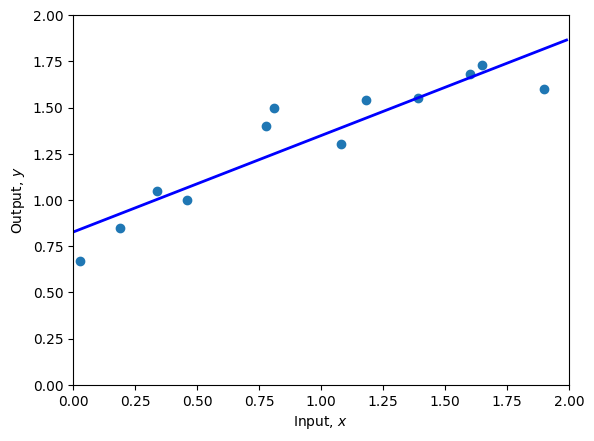

In [13]:
# Step 5: Plot the data and the model with optimal parameters
plot(x,y,w[0],w[1])
